# Czy położenie pomaga wykrywać znaki i sygnalizatory?

Porównujemy trzy klasyczne detektory na identycznych zdjęciach BDD100K. Wszystkie korzystają z tego samego generatora ramek i z tego samego SVM dla danej klasy. Zmieniamy wyłącznie sposób wykorzystania położenia.

| Wariant | Ocena kandydata |
|---|---|
| SVM | Wygląd wycinka (HOG) |
| SVM + odcięcie | Wygląd i odrzucenie ramek ze środkiem poniżej 75% wysokości |
| SVM + mapa | Wygląd i miękka ocena położenia z mapy 2D |

Eksperyment dotyczy lokalizacji. Każdy sygnalizator stanowi jedną klasę niezależnie od koloru światła.

## 1. Dane i podział

Z archiwum bierzemy etykiety pasujące po nazwie do zdjęć. Oficjalny podział detekcji decyduje o przynależności obrazu, również gdy jego plik JPG leży w inaczej nazwanym katalogu paczki 10K. Z oficjalnego train wydzielamy trening i strojenie. Oficjalny val służy jako końcowy test.

In [1]:
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

from prepare_dataset import CLASSES, DATASET, prepare
from spatial_prior import ocen_polozenie, zbuduj_mape

cv2.setNumThreads(1)
SEED = 42
IOU_MIN = 0.50
NMS_IOU = 0.30
CUTOFF = 0.75
TRAIN_COUNT = 2400
NAMES = ("SVM", "SVM + odcięcie", "SVM + mapa")
PL = {"traffic sign": "Znaki", "traffic light": "Sygnalizatory"}

if not DATASET.exists():
    prepare(Path("100k/bdd100k_labels.zip"))
dataset = json.loads(DATASET.read_text(encoding="utf-8"))
order = np.random.default_rng(SEED).permutation(len(dataset["train"]))
train = [dataset["train"][i] for i in order[:TRAIN_COUNT]]
val = [dataset["train"][i] for i in order[TRAIN_COUNT:]]
test = dataset["val"]
assert len({row["image"] for row in train + val + test}) == len(train + val + test)
print(f"Trening: {len(train)} | Strojenie: {len(val)} | Test: {len(test)} zdjęć")

Trening: 2400 | Strojenie: 576 | Test: 454 zdjęć


## 2. Kandydaci i cechy

MSER szuka stabilnych obszarów w obrazie szarym. Maski HSV dodają czerwone, żółte, zielone i niebieskie plamy. Dla jasnych obszarów w kolorach lamp dodajemy też pionowe ramki obejmujące fragment otoczenia. Wszystkie propozycje przenosimy do oryginalnej rozdzielczości obrazu i usuwamy identyczne ramki. Kandydat trafia w klasę, jeśli jego IoU z przynajmniej jedną ramką referencyjną tej klasy wynosi co najmniej 0,50. HOG opisuje kierunki krawędzi w wycinku 32 × 32.

In [2]:
HOG = cv2.HOGDescriptor((32, 32), (16, 16), (8, 8), (8, 8), 9)
MSER = cv2.MSER_create(5, 12, 4000)
HSV_RANGES = (
    ((0, 95, 100), (10, 255, 255)),
    ((168, 95, 100), (179, 255, 255)),
    ((11, 100, 135), (35, 255, 255)),
    ((36, 100, 125), (95, 255, 255)),
    ((96, 105, 80), (132, 255, 255)),
)


def candidate_boxes(image, gray):
    # MSER w obrazie szarym i komponenty kolorów w oryginalnej skali.
    _, regions = MSER.detectRegions(gray)
    boxes = [(x, y, x + w, y + h) for x, y, w, h in regions]
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    height, width = gray.shape
    for index, (lower, upper) in enumerate(HSV_RANGES):
        mask = cv2.inRange(hsv, lower, upper)
        _, _, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
        for x, y, w, h, area in stats[1:]:
            if area < 9 or min(w, h) < 3 or max(w, h) > 128:
                continue
            boxes.append((x, y, x + w, y + h))
            if index < 4 and max(w, h) <= 28:
                # Kolorowa plama może być jedną lampą większego sygnalizatora.
                for above, below in ((0.5, 2.0), (2.0, 0.5)):
                    boxes.append((
                        max(0, x - w // 3), max(0, y - round(above * h)),
                        min(width, x + w + w // 3), min(height, y + h + round(below * h)),
                    ))
    return np.array(sorted({
        (x1, y1, x2, y2) for x1, y1, x2, y2 in boxes
        if 4 <= x2 - x1 <= 160 and 4 <= y2 - y1 <= 160
    }), dtype=np.int32).reshape(-1, 4)


def iou_matrix(boxes, truth):
    overlap = np.minimum(boxes[:, None, 2:], truth[:, 2:]) - np.maximum(boxes[:, None, :2], truth[:, :2])
    intersection = np.maximum(overlap, 0).prod(axis=2)
    union = (boxes[:, 2:] - boxes[:, :2]).prod(axis=1)[:, None] + (truth[:, 2:] - truth[:, :2]).prod(axis=1) - intersection
    return intersection / union


def ground_truth(row, category, width, height):
    raw = [list(obj["box2d"][k] for k in ("x1", "y1", "x2", "y2"))
           for obj in row["objects"] if obj["category"] == category]
    boxes = np.array(raw, dtype=np.float32).reshape(-1, 4)
    boxes = boxes.clip(0, [width, height, width, height])
    return boxes[np.all(boxes[:, 2:] > boxes[:, :2], axis=1)]


def read_image(row):
    image = cv2.imread(row["image"])
    if image is None:
        raise FileNotFoundError(row["image"])
    return image


def extract(row):
    image = read_image(row)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    h, w = gray.shape
    boxes = candidate_boxes(image, gray)
    centers = (boxes[:, :2] + boxes[:, 2:]) / [2 * w, 2 * h]
    features = np.empty((len(boxes), HOG.getDescriptorSize()), dtype=np.float32)
    for i, (x1, y1, x2, y2) in enumerate(boxes):
        crop = cv2.resize(gray[y1:y2, x1:x2], (32, 32), interpolation=cv2.INTER_LINEAR)
        features[i] = HOG.compute(crop).ravel()
    overlaps = {c: iou_matrix(boxes, ground_truth(row, c, w, h)) for c in CLASSES}
    return boxes, centers, features, overlaps

## 3. Trening SVM i mapa położenia

Dla każdej klasy uczymy liniowy SVM na wszystkich trafieniach i na maksymalnie 40 przykładowych ramkach tła z każdego zdjęcia. Standaryzujemy cechy, a wagi klas pomagają przy przewadze przykładów tła. Mapa dostaje wszystkie kandydatury. W jej polach liczymy wygładzony udział trafień, więc przy małej liczbie kandydatów ocena zbliża się do średniej dla całego kadru.

In [3]:
def train_models(rows):
    rng = np.random.default_rng(SEED)
    train_x = {c: [] for c in CLASSES}
    train_y = {c: [] for c in CLASSES}
    all_centers = []
    all_hits = {c: [] for c in CLASSES}
    for i, row in enumerate(rows, 1):
        _, centers, features, overlaps = extract(row)
        all_centers.append(centers)
        for c in CLASSES:
            hits = (overlaps[c] >= IOU_MIN).any(axis=1)
            all_hits[c].append(hits)
            background = np.flatnonzero(~hits)
            sampled = rng.choice(background, size=min(40, len(background)), replace=False)
            chosen = np.r_[np.flatnonzero(hits), sampled]
            train_x[c].append(features[chosen])
            train_y[c].append(hits[chosen])
        if i % 400 == 0:
            print(f"Trening – opisano {i}/{len(rows)} zdjęć", flush=True)

    centers = np.concatenate(all_centers)
    svms, maps = {}, {}
    for c in CLASSES:
        y = np.concatenate(train_y[c])
        svms[c] = make_pipeline(StandardScaler(), LinearSVC(class_weight="balanced", dual=False, random_state=SEED))
        svms[c].fit(np.concatenate(train_x[c]), y)
        maps[c] = zbuduj_mape(centers, np.concatenate(all_hits[c]))
        print(f"{PL[c]}: {y.sum():,} trafień do SVM / {len(centers):,} kandydatów do mapy")
    return svms, maps


svms, maps = train_models(train)

Trening – opisano 400/2400 zdjęć
Trening – opisano 800/2400 zdjęć
Trening – opisano 1200/2400 zdjęć
Trening – opisano 1600/2400 zdjęć
Trening – opisano 2000/2400 zdjęć
Trening – opisano 2400/2400 zdjęć
Znaki: 10,678 trafień do SVM / 3,121,594 kandydatów do mapy
Sygnalizatory: 6,555 trafień do SVM / 3,121,594 kandydatów do mapy


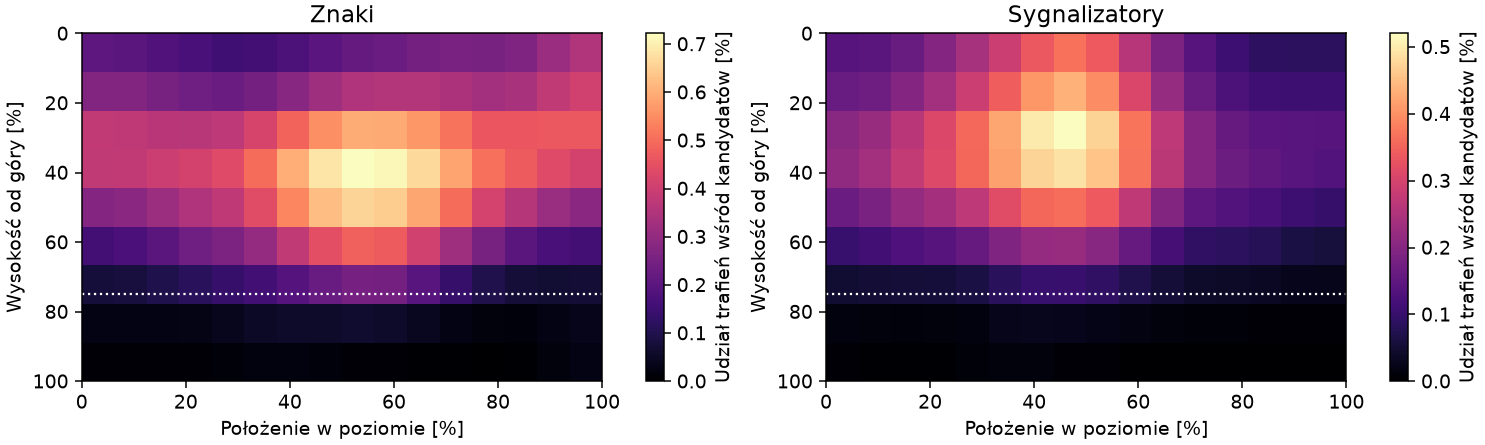

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), layout="constrained")
for ax, c in zip(axes, CLASSES):
    heatmap = ax.imshow(100 * maps[c], cmap="magma", extent=(0, 100, 100, 0), vmin=0, aspect="auto")
    ax.axhline(100 * CUTOFF, color="white", linestyle=":", linewidth=1.2)
    ax.set(title=PL[c], xlabel="Położenie w poziomie [%]", ylabel="Wysokość od góry [%]")
    fig.colorbar(heatmap, ax=ax, label="Udział trafień wśród kandydatów [%]")
plt.show()

## 4. Strojenie i test

Na walidacji uczymy regresję logistyczną na dwóch liczbach: wyniku SVM i logarytmie szans z mapy. Dla każdego wariantu i każdej klasy dobieramy próg maksymalizujący F1 na walidacji. Ten sam próg stosujemy potem na teście.

NMS usuwa nakładające się predykcje tej samej klasy w kolejności od najwyższej oceny. Każda zachowana predykcja może trafić w co najwyżej jedną jeszcze niewykorzystaną ramkę referencyjną. Próg decyzji i NMS stosujemy w obrębie każdej klasy.

In [5]:
def score_images(rows, split):
    scored = {c: [] for c in CLASSES}
    for i, row in enumerate(rows, 1):
        boxes, centers, x, overlaps = extract(row)
        for c in CLASSES:
            appearance = svms[c].decision_function(x) if len(x) else np.empty(0)
            p = ocen_polozenie(maps[c], centers)
            inputs = np.column_stack((appearance, np.log(p / (1 - p))))
            scored[c].append((boxes, centers, inputs, overlaps[c]))
        if i % 250 == 0 or i == len(rows):
            print(f"{split}: {i}/{len(rows)} zdjęć", flush=True)
    return scored


def fit_fusion(rows):
    inputs = np.concatenate([r[2] for r in rows])
    hits = np.concatenate([(r[3] >= IOU_MIN).any(axis=1) for r in rows])
    model = make_pipeline(StandardScaler(), LogisticRegression())
    return model.fit(inputs, hits)


def rank_image(row, variant, fusion):
    boxes, centers, inputs, overlaps = row
    if not len(boxes):
        return np.empty(0, int), np.empty(0), np.empty(0, int)
    scores = fusion.decision_function(inputs) if variant == NAMES[2] else inputs[:, 0]
    allowed = np.flatnonzero(centers[:, 1] <= CUTOFF) if variant == NAMES[1] else np.arange(len(boxes))
    if not len(allowed):
        return np.empty(0, int), np.empty(0), np.empty(0, int)
    xywh = boxes[allowed].copy()
    xywh[:, 2:] -= xywh[:, :2]
    nms_scores = (scores[allowed] - scores[allowed].min() + 1).tolist()
    keep = cv2.dnn.NMSBoxes(xywh.tolist(), nms_scores, 0, NMS_IOU)
    ids = allowed[np.asarray(keep, dtype=int).ravel()]
    ids = ids[np.argsort(-scores[ids], kind="stable")]
    ious = overlaps[ids].copy()
    matched = np.full(len(ids), -1)
    if ious.shape[1]:
        for i, values in enumerate(ious):
            j = values.argmax()
            if values[j] >= IOU_MIN:
                matched[i] = j
                ious[i + 1:, j] = -1
    return ids, scores[ids], matched


def choose_threshold(ranked, total_truth):
    scores = np.concatenate([r[1] for r in ranked])
    hits = np.concatenate([r[2] >= 0 for r in ranked])
    if not len(scores) or not hits.any():
        return np.inf
    order = np.argsort(-scores, kind="stable")
    scores, hits = scores[order], hits[order]
    ends = np.flatnonzero(np.r_[scores[:-1] != scores[1:], True])
    f1 = 2 * np.cumsum(hits)[ends] / (total_truth + ends + 1)
    return scores[ends[f1.argmax()]]


def above_threshold(ranked, threshold):
    return [(ids[scores >= threshold], matched[scores >= threshold]) for ids, scores, matched in ranked]


def counts(predictions, number_truth):
    tp = sum((matched >= 0).sum() for _, matched in predictions)
    fp = sum((matched < 0).sum() for _, matched in predictions)
    return int(tp), int(fp), int(number_truth - tp)


val_scores = score_images(val, "Strojenie")
fusions = {c: fit_fusion(val_scores[c]) for c in CLASSES}
thresholds = {
    (c, v): choose_threshold([rank_image(row, v, fusions[c]) for row in val_scores[c]],
                             sum(row[3].shape[1] for row in val_scores[c]))
    for c in CLASSES for v in NAMES
}

test_scores = score_images(test, "Test")
predictions, results = {}, {}
print(f"{'Klasa':16} {'Wariant':16} {'TP':>5} {'FP':>5} {'FN':>5} {'Prec.':>7} {'Recall':>7} {'F1':>7}")
for c in CLASSES:
    total_truth = sum(row[3].shape[1] for row in test_scores[c])
    for v in NAMES:
        ranked = [rank_image(row, v, fusions[c]) for row in test_scores[c]]
        predictions[c, v] = above_threshold(ranked, thresholds[c, v])
        tp, fp, fn = counts(predictions[c, v], total_truth)
        precision = tp / max(tp + fp, 1)
        recall = tp / max(tp + fn, 1)
        f1 = 2 * tp / max(2 * tp + fp + fn, 1)
        results[c, v] = (precision, recall, f1)
        print(f"{PL[c]:16} {v:16} {tp:5d} {fp:5d} {fn:5d} {precision:7.3f} {recall:7.3f} {f1:7.3f}")

for c in CLASSES:
    covered = sum((row[3] >= IOU_MIN).any(axis=0).sum() for row in test_scores[c])
    total = sum(row[3].shape[1] for row in test_scores[c])
    prior_weight = fusions[c].named_steps["logisticregression"].coef_[0, 1]
    print(f"{PL[c]}: recall propozycji {covered}/{total} = {covered/total:.1%} | waga mapy po standaryzacji = {prior_weight:+.2f}")

Strojenie: 250/576 zdjęć
Strojenie: 500/576 zdjęć
Strojenie: 576/576 zdjęć
Test: 250/454 zdjęć
Test: 454/454 zdjęć
Klasa            Wariant             TP    FP    FN   Prec.  Recall      F1
Znaki            SVM                165  2396  1598   0.064   0.094   0.076
Znaki            SVM + odcięcie     165  2325  1598   0.066   0.094   0.078
Znaki            SVM + mapa         142  2033  1621   0.065   0.081   0.072
Sygnalizatory    SVM                 52  1599  1139   0.031   0.044   0.037
Sygnalizatory    SVM + odcięcie      52  1528  1139   0.033   0.044   0.038
Sygnalizatory    SVM + mapa          59   982  1132   0.057   0.050   0.053
Znaki: recall propozycji 733/1763 = 41.6% | waga mapy po standaryzacji = +1.21
Sygnalizatory: recall propozycji 504/1191 = 42.3% | waga mapy po standaryzacji = +1.09


## 5. Zdjęcia przed i po detekcji

Na tych samych obrazach pokazujemy surowy kadr, ramki z etykiet i wyniki wszystkich wariantów. Zielone ramki to trafienia, czerwone to fałszywe alarmy, a pomarańczowe przerywane to pominięte obiekty. Dla każdej klasy szukamy przykładu, na którym mapa odzyskuje obiekt, oraz przykładu jej błędu względem samego SVM. To ilustracje wybrane po teście. Porównanie ogólne pochodzi z tabeli dla wszystkich 454 zdjęć.

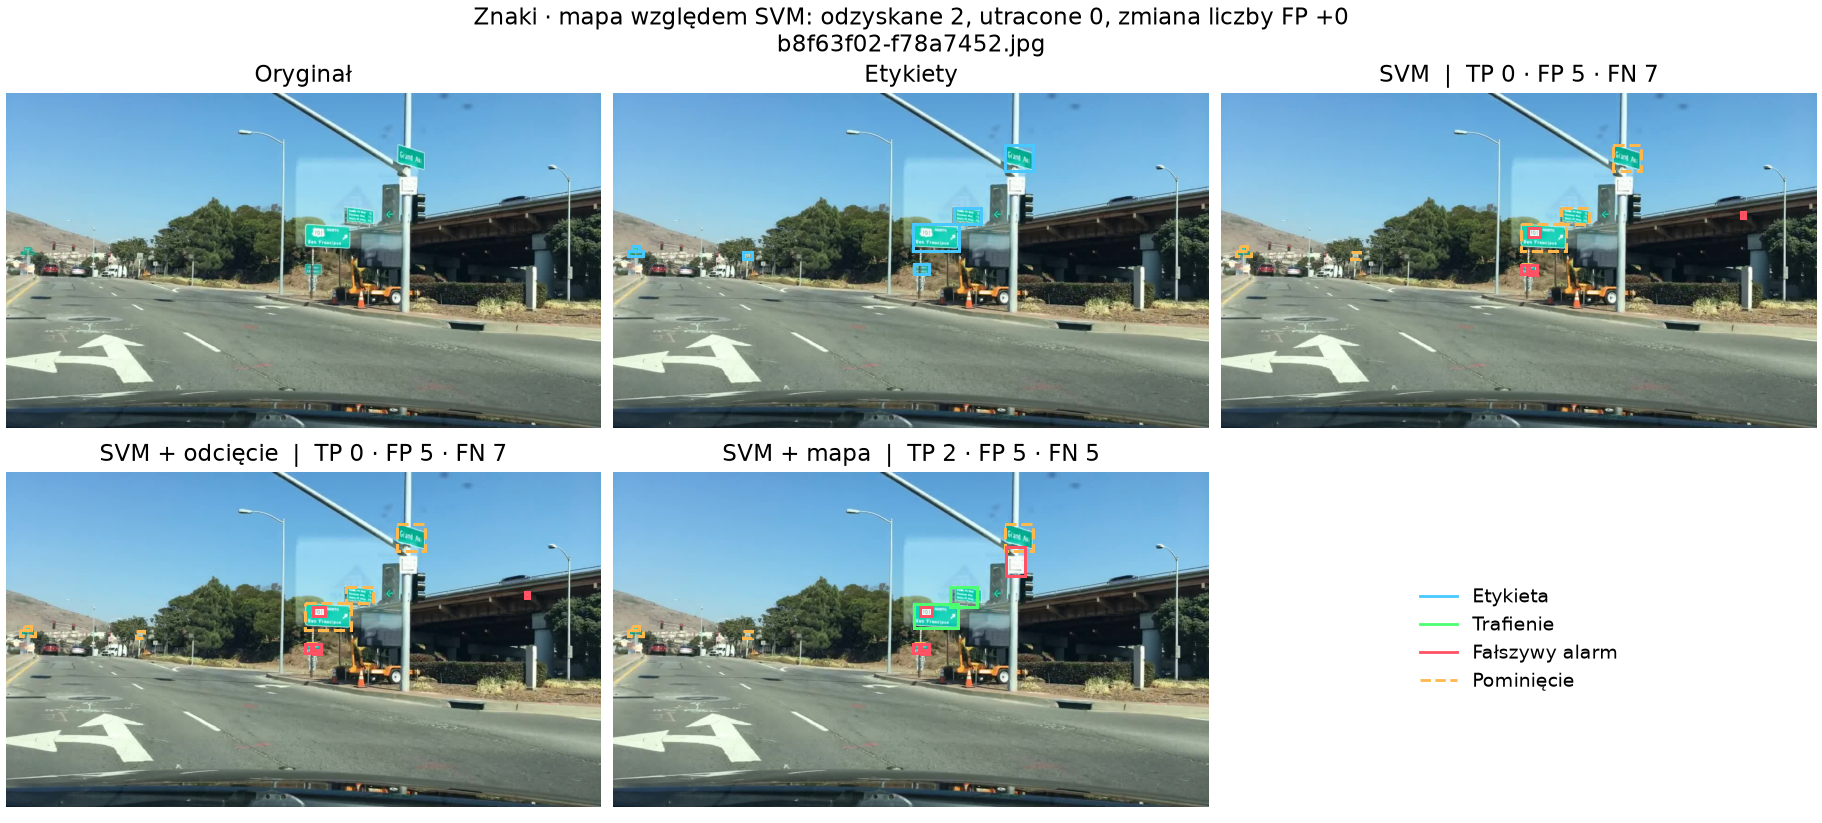

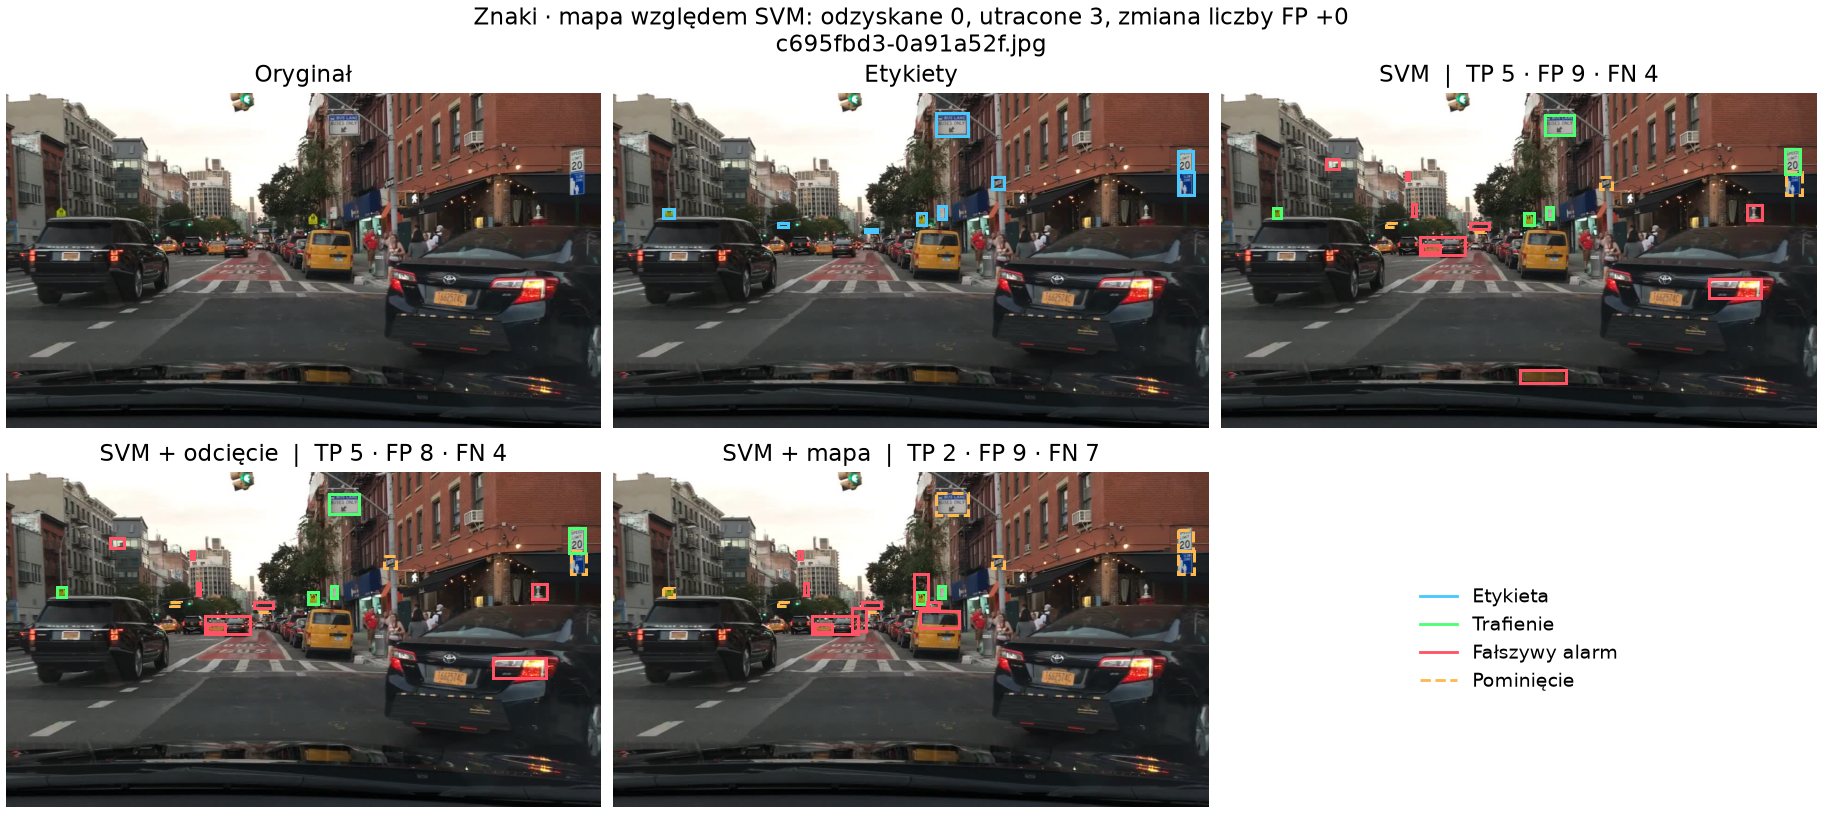

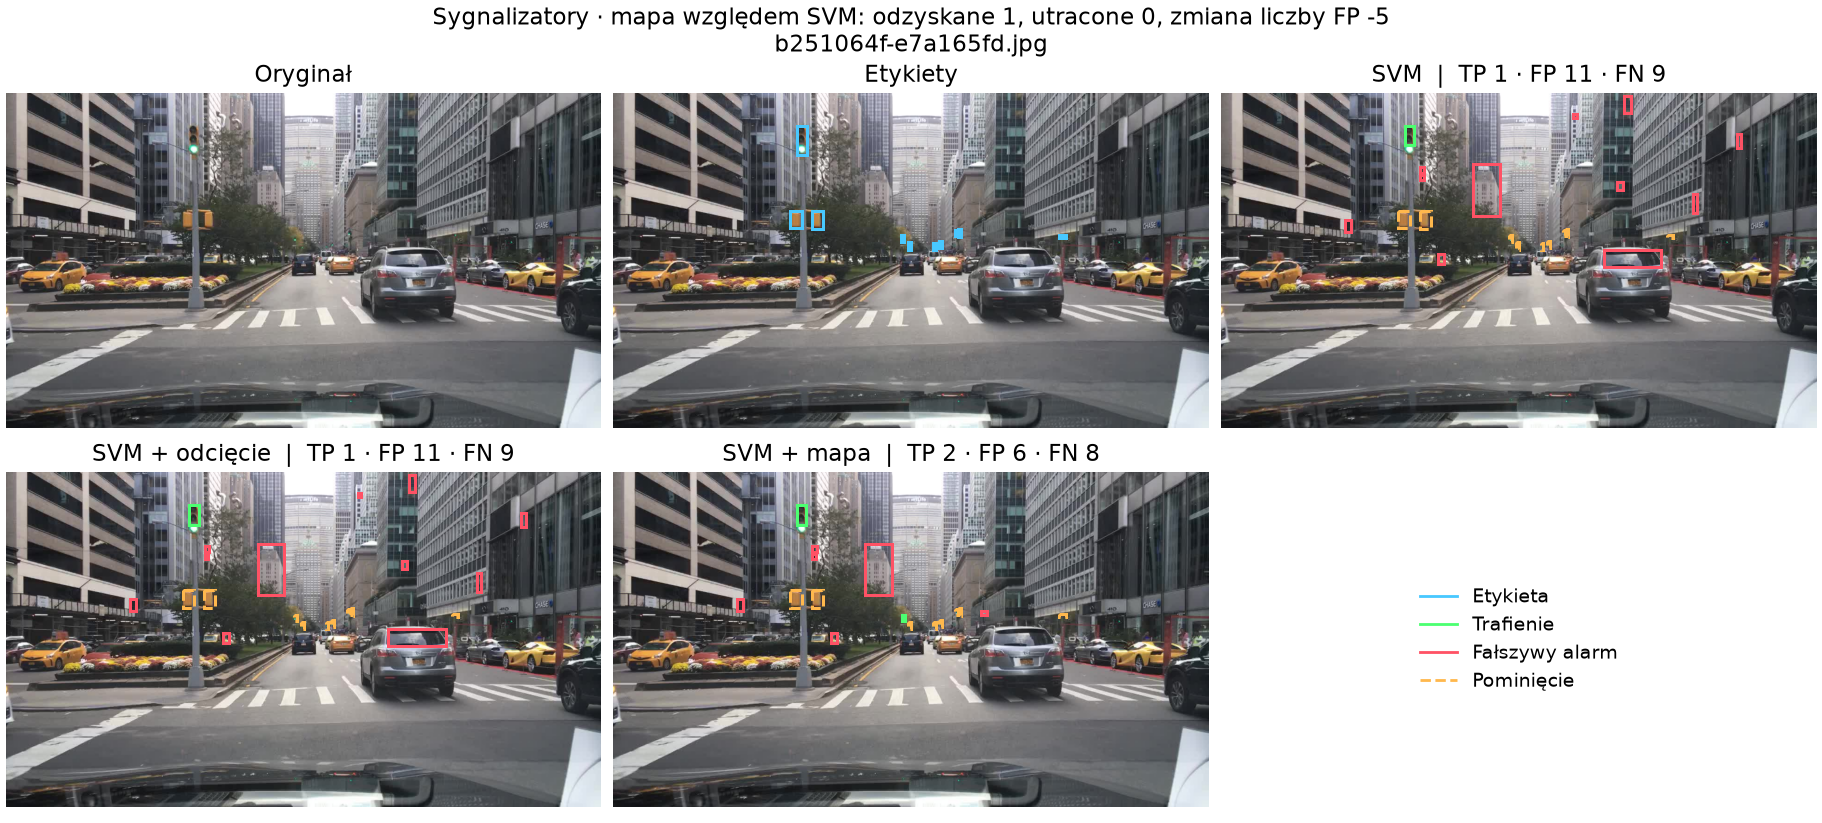

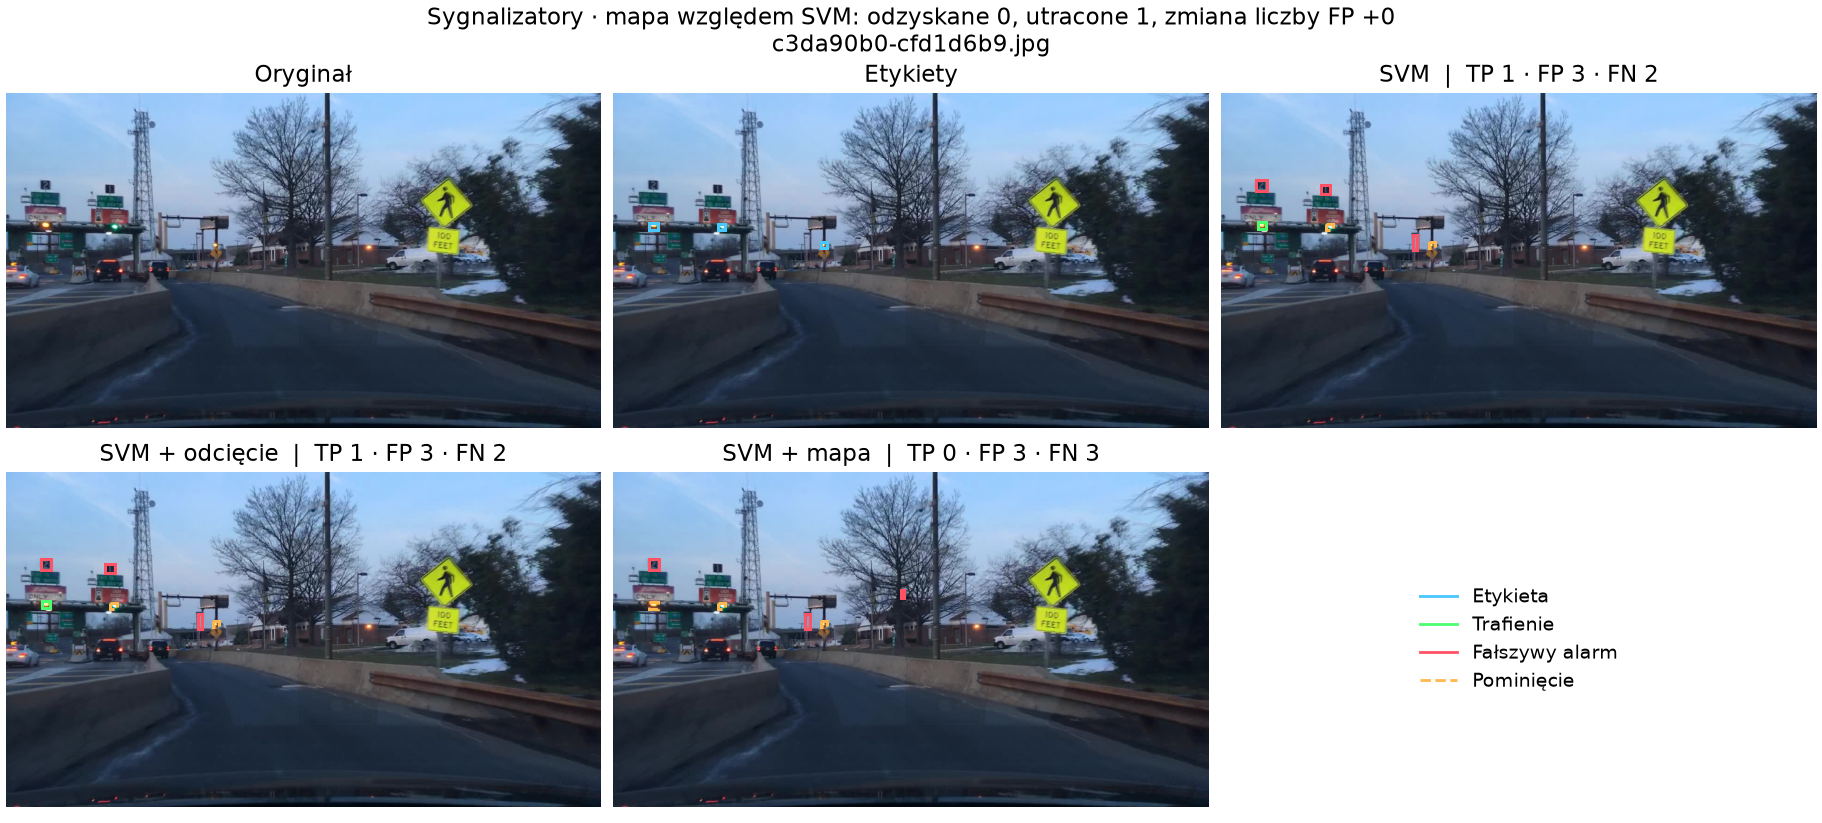

In [6]:
def mark(ax, boxes, color, linestyle="-"):
    for x1, y1, x2, y2 in boxes:
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                               fill=False, edgecolor=color, linewidth=1.6, linestyle=linestyle))


def show_example(i, c, caption):
    row = test[i]
    image = cv2.cvtColor(read_image(row), cv2.COLOR_BGR2RGB)
    h, w = image.shape[:2]
    truth = ground_truth(row, c, w, h)
    boxes = test_scores[c][i][0]
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 6.1), layout="constrained")
    panels = axes.flat
    for ax in panels:
        ax.axis("off")
    for ax, title in zip(axes.flat, ("Oryginał", "Etykiety", "SVM", "SVM + odcięcie", "SVM + mapa")):
        ax.imshow(image)
        ax.set_title(title)
        if title == "Etykiety":
            mark(ax, truth, "#48c8ff")
        if title in NAMES:
            ids, matched = predictions[c, title][i]
            hits = matched >= 0
            missed = np.setdiff1d(np.arange(len(truth)), matched[hits])
            mark(ax, truth[missed], "#ffb84d", "--")
            mark(ax, boxes[ids[hits]], "#4cff71")
            mark(ax, boxes[ids[~hits]], "#ff5265")
            ax.set_title(f"{title}  |  TP {hits.sum()} · FP {(~hits).sum()} · FN {len(missed)}")
    axes[1, 2].legend(handles=[
        Line2D([0], [0], color="#48c8ff", label="Etykieta"),
        Line2D([0], [0], color="#4cff71", label="Trafienie"),
        Line2D([0], [0], color="#ff5265", label="Fałszywy alarm"),
        Line2D([0], [0], color="#ffb84d", linestyle="--", label="Pominięcie"),
    ], loc="center", frameon=False)
    fig.suptitle(f"{PL[c]} · {caption}\n{Path(row['image']).name}")
    plt.show()


def example_changes(c, i):
    _, baseline = predictions[c, NAMES[0]][i]
    _, spatial = predictions[c, NAMES[2]][i]
    base_hits, map_hits = set(baseline[baseline >= 0]), set(spatial[spatial >= 0])
    change_fp = int((spatial < 0).sum() - (baseline < 0).sum())
    return len(map_hits - base_hits), len(base_hits - map_hits), change_fp


for c in CLASSES:
    changes = [example_changes(c, i) for i in range(len(test))]
    best = max(range(len(test)), key=lambda i: (changes[i][0] - changes[i][1], -changes[i][2]))
    worst = max((i for i in range(len(test)) if i != best),
                key=lambda i: (changes[i][1] - changes[i][0], changes[i][2]))
    for i in (best, worst):
        gained, lost, fp_delta = changes[i]
        caption = f"mapa względem SVM: odzyskane {gained}, utracone {lost}, zmiana liczby FP {fp_delta:+d}"
        show_example(i, c, caption)

In [7]:
print("Co zmieniła mapa na całym teście?")
for c in CLASSES:
    spatial = np.array(results[c, NAMES[2]])
    baseline = np.array(results[c, NAMES[0]])
    cutoff = np.array(results[c, NAMES[1]])
    delta = 100 * (spatial - baseline)
    print(f"{PL[c]}: mapa vs SVM: precision {delta[0]:+.2f}, recall {delta[1]:+.2f}, F1 {delta[2]:+.2f} p.p.")
    print(f"  Mapa vs odcięcie: ΔF1 {100 * (spatial[2] - cutoff[2]):+.2f} p.p.")
    below_truth = 0
    below_hits = dict.fromkeys(NAMES, 0)
    for i, row in enumerate(test):
        # Wszystkie obrazy tego zestawu mają 1280 × 720 px.
        gt = ground_truth(row, c, 1280, 720)
        below = (gt[:, 1] + gt[:, 3]) / 2 > CUTOFF * 720
        below_truth += below.sum()
        for v in NAMES:
            matched = predictions[c, v][i][1]
            below_hits[v] += below[matched[matched >= 0]].sum()
    print(f"  Trafienia w obiekty ze środkiem poniżej linii ({below_truth} GT): "
          + ", ".join(f"{v} {below_hits[v]}" for v in NAMES))

Co zmieniła mapa na całym teście?
Znaki: mapa vs SVM: precision +0.09, recall -1.30, F1 -0.42 p.p.
  Mapa vs odcięcie: ΔF1 -0.55 p.p.
  Trafienia w obiekty ze środkiem poniżej linii (1 GT): SVM 0, SVM + odcięcie 0, SVM + mapa 0
Sygnalizatory: mapa vs SVM: precision +2.52, recall +0.59, F1 +1.63 p.p.
  Mapa vs odcięcie: ΔF1 +1.53 p.p.
  Trafienia w obiekty ze środkiem poniżej linii (3 GT): SVM 0, SVM + odcięcie 0, SVM + mapa 0


## 6. Wnioski z tego uruchomienia

- **Sygnalizatory.** Mapa zmniejszyła liczbę fałszywych alarmów z 1599 do 982, a liczba trafień wzrosła z 52 do 59. Na zdjęciu `b251064f-e7a165fd.jpg` odpada m.in. ramka na tylnej szybie samochodu, a dochodzi mały sygnalizator w głębi ulicy. Na `c3da90b0-cfd1d6b9.jpg` mapa pomija prawdziwe światło z lewej strony kadru, które wykrywa sam SVM.
- **Znaki.** Mapa zmniejszyła liczbę fałszywych alarmów z 2396 do 2033, ale zmniejszyła też liczbę trafień ze 165 do 142. Na `b8f63f02-f78a7452.jpg` odzyskuje dwie zielone tablice kierunkowe, a na `c695fbd3-0a91a52f.jpg` gubi m.in. tablicę ponad ulicą i znak ograniczenia prędkości przy prawej krawędzi. W całym teście najwyższe F1 dla znaków uzyskał wariant z odcięciem.
- **Ograniczenie generatora.** Przy IoU ≥ 0,50 kandydaci pokryli 41,6% znaków i 42,3% sygnalizatorów. Końcowy recall wszystkich wariantów był wyraźnie niższy. Spośród czterech obiektów ze środkiem poniżej linii 75% żaden wariant nie wykrył żadnego. Ta próba daje za mało przykładów, by ocenić korzyści zachowania dolnej części kadru.


## 7. Gdzie detektor traci obiekty?

Diagnozę liczymy na tych samych 576 zdjęciach ze zbioru do strojenia, przy wcześniej dobranych progach. Każdą etykietę przypisujemy do pierwszej przeszkody: brak kandydata z IoU ≥ 0,50, odcięcie dołu, próg wyniku, NMS albo dopasowanie jeden do jednego. Ostatni przypadek oznacza, że ramka o wystarczającym IoU pozostała, ale została już przypisana do innego obiektu.

Podział rozmiarów korzysta z pierwiastka z pola ramki w pikselach. Próg i NMS oceniamy w tej kolejności, bo ramka poniżej progu nie usuwa w NMS ramki o wyższym wyniku. Wyniki są diagnostyką wariantów strojonych na tych zdjęciach.


Znaki
Wariant             Rozmiar   Brak ramki     Odcięcie         Próg          NMS  Dopasowanie      Wykryte
SVM                   Razem         1208            0          772            9            0          162
SVM                  <16 px          419            0          240            0            0           20
SVM               16–<32 px          542            0          344            4            0           72
SVM                  ≥32 px          247            0          188            5            0           70
SVM + odcięcie        Razem         1208            0          772            9            0          162
SVM + odcięcie       <16 px          419            0          240            0            0           20
SVM + odcięcie    16–<32 px          542            0          344            4            0           72
SVM + odcięcie       ≥32 px          247            0          188            5            0           70
SVM + mapa            Razem         120

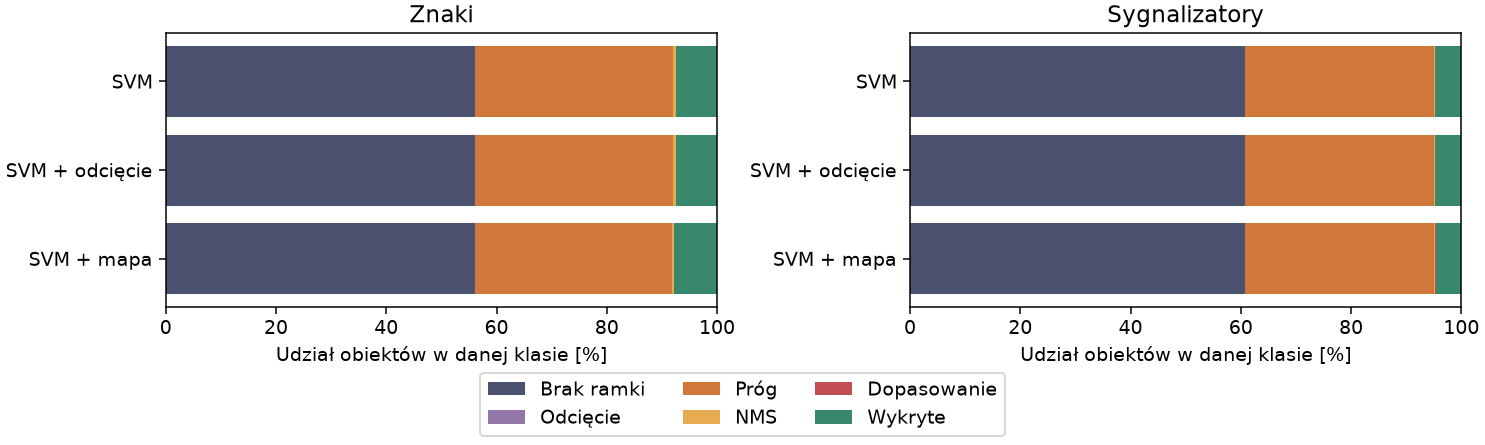

In [8]:
STAGES = ("Brak ramki", "Odcięcie", "Próg", "NMS", "Dopasowanie", "Wykryte")
SIZE_BINS = ((0, 16), (16, 32), (32, np.inf))
SIZE_NAMES = ("<16 px", "16–<32 px", "≥32 px")


def diagnostic_masks(scored, variant, fusion, threshold):
    _, centers, inputs, overlaps = scored
    hit = overlaps >= IOU_MIN
    allowed = centers[:, 1] <= CUTOFF if variant == NAMES[1] else np.ones(len(centers), dtype=bool)
    scores = fusion.decision_function(inputs) if variant == NAMES[2] and len(inputs) else inputs[:, 0]
    ids, ranked_scores, matched = rank_image(scored, variant, fusion)
    kept = ranked_scores >= threshold
    detected = np.zeros(hit.shape[1], dtype=bool)
    detected[matched[kept & (matched >= 0)]] = True
    stages = [
        np.ones(hit.shape[1], dtype=bool),
        hit.any(axis=0),
        hit[allowed].any(axis=0),
        hit[allowed & (scores >= threshold)].any(axis=0),
        hit[ids[kept]].any(axis=0),
        detected,
    ]
    assert all(np.all(~after | before) for before, after in zip(stages, stages[1:]))
    return np.stack([before & ~after for before, after in zip(stages, stages[1:])] + [detected])


diagnostics = {}
for c in CLASSES:
    for v in NAMES:
        by_size = np.zeros((len(SIZE_BINS), len(STAGES)), dtype=int)
        for row, scored in zip(val, val_scores[c]):
            truth = ground_truth(row, c, 1280, 720)
            side = np.sqrt((truth[:, 2:] - truth[:, :2]).prod(axis=1))
            masks = diagnostic_masks(scored, v, fusions[c], thresholds[c, v])
            for i, (low, high) in enumerate(SIZE_BINS):
                by_size[i] += masks[:, (side >= low) & (side < high)].sum(axis=1)
        assert by_size.sum() == sum(row[3].shape[1] for row in val_scores[c])
        diagnostics[c, v] = by_size

for c in CLASSES:
    print(f"\n{PL[c]}")
    print(f"{'Wariant':17} {'Rozmiar':>9}" + "".join(f"{stage:>13}" for stage in STAGES))
    for v in NAMES:
        by_size = diagnostics[c, v]
        for label, row in zip(("Razem", *SIZE_NAMES), np.vstack((by_size.sum(axis=0), by_size))):
            print(f"{v:17} {label:>9}" + "".join(f"{n:13d}" for n in row))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), layout="constrained")
colors = ("#4b5270", "#9176a7", "#d07839", "#e7ac51", "#c24f53", "#38896b")
for ax, c in zip(axes, CLASSES):
    counts_by_variant = np.stack([diagnostics[c, v].sum(axis=0) for v in NAMES])
    shares = 100 * counts_by_variant / counts_by_variant.sum(axis=1, keepdims=True)
    left = np.zeros(len(NAMES))
    for stage, widths, color in zip(STAGES, shares.T, colors):
        ax.barh(NAMES, widths, left=left, label=stage, color=color)
        left += widths
    ax.invert_yaxis()
    ax.set(title=PL[c], xlim=(0, 100), xlabel="Udział obiektów w danej klasie [%]")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3)
plt.show()

**Wariant odniesienia (sam SVM).** Brak odpowiedniej ramki wyjaśnia 1208 z 2151 obiektów w klasie znaków (56,2%) i 877 z 1444 sygnalizatorów (60,7%). Próg wyniku zatrzymuje kolejne 772 znaki i 495 sygnalizatorów. Na etapie NMS odpada 9 znaków i 2 sygnalizatory.

**Najmniejsze obiekty.** Dla ramek poniżej 16 px brak kandydata dotyczy 419 z 679 znaków (61,7%) i 438 z 624 sygnalizatorów (70,2%). Wyniki wskazują na dwa główne źródła pominięć: propozycje ramek i ocena kandydatów. Próg dobrano według F1, więc jego obniżenie może zwiększyć liczbę trafień kosztem większej liczby fałszywych alarmów.